In [21]:
import os
import re
import json
import time
import hashlib
from datetime import datetime, timezone
from email.utils import parsedate_to_datetime
import requests
import numpy as np
import pandas as pd

from pathlib import Path
from dotenv import load_dotenv
from tqdm.auto import tqdm
from qdrant_client import QdrantClient
from rank_bm25 import BM25Okapi
from pythainlp.tokenize import word_tokenize

PROJECT_ROOT = Path(r"D:\Project_Github\gold assisstant")

GT_PATH = Path(r"D:\Project_Github\gold assisstant\embedding\embedding\ground_truth_queries_v2.jsonl")
CHUNKS_PATH = Path(r"D:\Project_Github\gold assisstant\embedding\artifacts\chunking_real\structure_aware\chunks_structure_aware_real.jsonl")

OUTPUT_DIR = Path(r"D:\Project_Github\gold assisstant\rag\rag_comparison")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

load_dotenv(PROJECT_ROOT / ".env", override=True)

CLOUDFLARE_ACCOUNT_ID = os.getenv("CLOUDFLARE_ACCOUNT_ID")
CLOUDFLARE_API_TOKEN = os.getenv("CLOUDFLARE_API_TOKEN")
QDRANT_URL = os.getenv("QDRANT_URL")
QDRANT_API_KEY = os.getenv("QDRANT_API_KEY")
JINA_API_KEY = os.getenv("JINA_API_KEY")

COLLECTION_NAME = "gold_news_structure_aware"
EMBEDDING_MODEL = "@cf/baai/bge-m3"
RERANK_MODEL = "jina-reranker-v3.5"

# Set to a vector name only if your Qdrant collection uses named vectors.
QDRANT_VECTOR_NAME = os.getenv("QDRANT_VECTOR_NAME") or None

# Evaluate all 114 Ground Truth queries.
SAMPLE_N = None

DENSE_CANDIDATES = 40
BM25_CANDIDATES = 40
HYBRID_CANDIDATES = 40
FINAL_K = 10

# Limit text sent to the hosted reranker to control token consumption.
JINA_MAX_CHARS_PER_DOCUMENT = 2500
JINA_MAX_RETRIES = 5
JINA_MAX_RETRY_WAIT_SECONDS = 120

required = {
    "CLOUDFLARE_ACCOUNT_ID": CLOUDFLARE_ACCOUNT_ID,
    "CLOUDFLARE_API_TOKEN": CLOUDFLARE_API_TOKEN,
    "QDRANT_URL": QDRANT_URL,
    "QDRANT_API_KEY": QDRANT_API_KEY,
    "JINA_API_KEY": JINA_API_KEY,
}

missing = [key for key, value in required.items() if not value]

if missing:
    raise ValueError(
        "Missing environment variables: " + ", ".join(missing)
    )

assert GT_PATH.exists(), f"Ground Truth file not found: {GT_PATH}"
assert CHUNKS_PATH.exists(), f"Chunks file not found: {CHUNKS_PATH}"

print("Configuration loaded")
print("Collection:", COLLECTION_NAME)
print("Reranker:", RERANK_MODEL)
print("Queries:", "all" if SAMPLE_N is None else SAMPLE_N)
#


Configuration loaded
Collection: gold_news_structure_aware
Reranker: jina-reranker-v3.5
Queries: all


In [22]:
def read_jsonl(path):
    records = []

    with open(path, "r", encoding="utf-8") as f:
        for line_no, line in enumerate(f, start=1):
            line = line.strip()

            if not line:
                continue

            try:
                records.append(json.loads(line))
            except json.JSONDecodeError as exc:
                raise ValueError(
                    f"Invalid JSON at {path}, line {line_no}: {exc}"
                )

    return records


def get_field(record, *names):
    if not isinstance(record, dict):
        return None

    containers = [
        record,
        record.get("metadata", {}),
        record.get("payload", {}),
    ]

    for container in containers:
        if not isinstance(container, dict):
            continue

        for name in names:
            value = container.get(name)

            if value is not None and value != "":
                return value

    return None


def normalize_chunk(record, index):
    text = get_field(
        record,
        "text",
        "chunk_text",
        "content",
        "page_content",
        "body",
    )

    if not isinstance(text, str) or not text.strip():
        return None

    chunk_id = get_field(record, "chunk_id", "id", "point_id")
    document_id = get_field(
        record, "document_id", "doc_id", "source_document_id"
    )

    return {
        "chunk_id": str(chunk_id) if chunk_id is not None else f"local_{index}",
        "document_id": str(document_id) if document_id is not None else None,
        "original_id": get_field(record, "original_id", "source_id"),
        "source_file": get_field(record, "source_file"),
        "url": get_field(record, "url", "source_url"),
        "text": text.strip(),
        "title": get_field(record, "title", "document_title"),
        "source": get_field(record, "source", "source_name"),
        "publication_date": get_field(
            record, "publication_date", "date"
        ),
        "report_period": get_field(record, "report_period"),
    }


raw_gt = read_jsonl(GT_PATH)
raw_chunks = read_jsonl(CHUNKS_PATH)

chunks = [
    item
    for i, record in enumerate(raw_chunks)
    if (item := normalize_chunk(record, i)) is not None
]

if not chunks:
    raise ValueError(
        "No usable chunks found. Inspect the JSONL schema and text fields."
    )

chunk_by_id = {c["chunk_id"]: c for c in chunks}

print("Ground Truth records:", len(raw_gt))
print("Usable chunks:", len(chunks))

print("\nGround Truth sample:")
display(pd.DataFrame(raw_gt).head(3))

print("\nChunk sample:")
display(pd.DataFrame(chunks).head(3))

Ground Truth records: 114
Usable chunks: 19784

Ground Truth sample:


,schema_version,query_id,query,query_language,query_type,difficulty,question_pattern_id,source_filter,source_scope,evidence,expected_answer,relevance_judgments,judgment_set_exhaustive,review_status,review_notes,created_by,split,split_group_ids
0,2.0,gtv2_000001,ตามรายงาน CPI ของสหรัฐฯ สำหรับ July 2016 ค่า C...,th,numeric_fact,easy,cpi_u_monthly_change,bls_cpi,[bls_cpi],"[{'evidence_id': 'gtv2_000001_e1', 'document_i...",{'text': 'The Consumer Price Index for All Urb...,"[{'document_id': 'bls_cpi_2016_07', 'relevance...",False,source_span_validated_needs_human_semantic_review,[Exact quote and character offsets were checke...,assistant_curated_source_grounded_v2,development,[bls_cpi:bls_cpi_2016_07]
1,2.0,gtv2_000002,What 12-month change in the all-items index di...,en,numeric_fact,easy,cpi_all_items_12m_change,bls_cpi,[bls_cpi],"[{'evidence_id': 'gtv2_000002_e1', 'document_i...","{'text': 'Over the last 12 months, the all ite...","[{'document_id': 'bls_cpi_2016_07', 'relevance...",False,source_span_validated_needs_human_semantic_review,[Exact quote and character offsets were checke...,assistant_curated_source_grounded_v2,development,[bls_cpi:bls_cpi_2016_07]
2,2.0,gtv2_000003,According to the U.S. CPI release for January ...,en,numeric_fact,easy,cpi_u_monthly_change,bls_cpi,[bls_cpi],"[{'evidence_id': 'gtv2_000003_e1', 'document_i...",{'text': 'The Consumer Price Index for All Urb...,"[{'document_id': 'bls_cpi_2023_01', 'relevance...",False,source_span_validated_needs_human_semantic_review,[Exact quote and character offsets were checke...,assistant_curated_source_grounded_v2,test,[bls_cpi:bls_cpi_2023_01]



Chunk sample:


,chunk_id,document_id,original_id,source_file,url,text,title,source,publication_date,report_period
0,ce67d31dde131c6cb141,b69cb2366d22735f,thaipbs:news:571381,D:\Project_Github\gold assisstant\dataset\news...,NaN,ราคาทองคำ ลบ 650 บาท ผันผวน 21 ครั้ง ทองลงขณะน...,สรุปราคาทองคำ 20 ต.ค.2569 ปิดตลาด ผันผวน 21 คร...,thai_pbs_gold,2026-10-20T17:52:29+07:00,NaN
1,8b1b212ec21ab98297d8,b69cb2366d22735f,thaipbs:news:571381,D:\Project_Github\gold assisstant\dataset\news...,NaN,ส่งผลให้กองทัพสหรัฐฯ และอิสราเอล กำลังอยู่ระหว...,สรุปราคาทองคำ 20 ต.ค.2569 ปิดตลาด ผันผวน 21 คร...,thai_pbs_gold,2026-10-20T17:52:29+07:00,NaN
2,37de06bdb8a88055745b,b69cb2366d22735f,thaipbs:news:571381,D:\Project_Github\gold assisstant\dataset\news...,NaN,อย่างไรก็ตาม ตลาดยังคงคาดการณ์เกิน 80% ว่าเฟดอ...,สรุปราคาทองคำ 20 ต.ค.2569 ปิดตลาด ผันผวน 21 คร...,thai_pbs_gold,2026-10-20T17:52:29+07:00,NaN


In [23]:
def tokenize(text):
    text = str(text).lower()
    tokens = word_tokenize(text, engine="newmm", keep_whitespace=False)
    return [token.strip() for token in tokens if token and token.strip()]


bm25_corpus = [tokenize(chunk["text"]) for chunk in chunks]
bm25 = BM25Okapi(bm25_corpus)

qdrant = QdrantClient(url=QDRANT_URL, api_key=QDRANT_API_KEY, timeout=60)
collection_info = qdrant.get_collection(COLLECTION_NAME)
print("Qdrant connected")
print("Points in collection:", collection_info.points_count)
print("Local chunks:", len(chunks))


Qdrant connected
Points in collection: 19784
Local chunks: 19784


In [24]:
CLOUDFLARE_EMBED_URL = (
    f"https://api.cloudflare.com/client/v4/accounts/"
    f"{CLOUDFLARE_ACCOUNT_ID}/ai/run/{EMBEDDING_MODEL}"
)


def cloudflare_embed(text, max_retries=4):
    headers = {
        "Authorization": f"Bearer {CLOUDFLARE_API_TOKEN}",
        "Content-Type": "application/json",
    }
    payload = {"text": [str(text)]}

    for attempt in range(max_retries):
        response = requests.post(
            CLOUDFLARE_EMBED_URL,
            headers=headers,
            json=payload,
            timeout=60,
        )
        if response.status_code == 429 or response.status_code >= 500:
            if attempt < max_retries - 1:
                time.sleep(2 ** attempt)
                continue
        response.raise_for_status()
        body = response.json()
        if body.get("success") is False:
            raise RuntimeError(f"Cloudflare embedding failed: {body.get('errors')}")

        result = body.get("result") or {}
        vectors = result.get("data")
        if vectors is None:
            vectors = result.get("embeddings")
        if vectors is None:
            raise ValueError(f"Cannot find embedding vectors in response: {list(result.keys())}")

        vector = vectors[0]
        if isinstance(vector, dict):
            vector = vector.get("embedding", vector.get("vector"))
        if not isinstance(vector, (list, tuple)):
            raise ValueError(f"Unexpected embedding format: {type(vector)}")

        vector = np.asarray(vector, dtype=np.float32)
        if vector.ndim != 1 or vector.size == 0:
            raise ValueError("Embedding vector is empty or invalid")
        return vector.tolist()

    raise RuntimeError("Cloudflare embedding retries exhausted")


In [25]:
def dense_search(query, top_k=DENSE_CANDIDATES):
    vector = cloudflare_embed(query)
    kwargs = {
        "collection_name": COLLECTION_NAME,
        "query": vector,
        "limit": top_k,
        "with_payload": True,
        "with_vectors": False,
    }
    if QDRANT_VECTOR_NAME:
        kwargs["using"] = QDRANT_VECTOR_NAME

    response = qdrant.query_points(**kwargs)
    results = []
    for point in response.points:
        payload = point.payload or {}
        normalized = normalize_chunk(payload, str(point.id))
        payload_chunk_id = get_field(payload, "chunk_id", "id", "point_id")
        local = chunk_by_id.get(str(payload_chunk_id)) if payload_chunk_id is not None else None
        item = dict(local) if local is not None else dict(normalized) if normalized is not None else None
        if item is None:
            continue
        item["dense_score"] = float(point.score)
        results.append(item)
    return results


def bm25_search(query, top_k=BM25_CANDIDATES):
    scores = bm25.get_scores(tokenize(query))
    indices = np.argsort(-scores, kind="stable")[:top_k]
    results = []
    for idx in indices:
        item = dict(chunks[int(idx)])
        item["bm25_score"] = float(scores[idx])
        results.append(item)
    return results


def result_identity(item):
    chunk_id = item.get("chunk_id")
    if chunk_id:
        return str(chunk_id)
    raw = str(item.get("document_id") or "") + "|" + str(item.get("text") or "")
    return hashlib.sha1(raw.encode("utf-8")).hexdigest()


def rrf_fusion(result_lists, k=60, top_k=HYBRID_CANDIDATES):
    fused = {}
    for results in result_lists:
        seen_in_list = set()
        for rank, item in enumerate(results, start=1):
            key = result_identity(item)
            if key in seen_in_list:
                continue
            seen_in_list.add(key)
            if key not in fused:
                fused[key] = {**item, "rrf_score": 0.0}
            fused[key]["rrf_score"] += 1.0 / (k + rank)
    ranked = sorted(fused.values(), key=lambda item: item["rrf_score"], reverse=True)
    return ranked[:top_k]


# Smoke test
test_query = "What did the Federal Reserve say about interest rates?"
dense_test = dense_search(test_query, top_k=5)
bm25_test = bm25_search(test_query, top_k=5)
hybrid_test = rrf_fusion([dense_test, bm25_test], top_k=5)
print("Dense results:", len(dense_test))
print("BM25 results:", len(bm25_test))
print("Hybrid results:", len(hybrid_test))
display(pd.DataFrame([
    {
        "rank": rank,
        "document_id": item.get("document_id"),
        "original_id": item.get("original_id"),
        "score": item.get("rrf_score"),
        "text": item["text"][:250],
    }
    for rank, item in enumerate(hybrid_test, start=1)
]))


Dense results: 5
BM25 results: 5
Hybrid results: 5


,rank,document_id,original_id,score,text
0,1,f9e072b2cd143876,21e49b2ffde44e713ebff0d6bcf5f75353d30796,0.016393,The Federal Open Market Committee decided toda...
1,2,ccddec773cc17347,54532cd0c6fe7cb4d194af6fc0122e71887438db,0.016393,The Federal Reserve Board on Tuesday announced...
2,3,f65573ae867f411a,0a4671a3a2fb933f858512d643a6bc95b343d938,0.016129,Board of Governors of the Federal Reserve Syst...
3,4,d5057b7bc3e11457,4babc1728bc7c3264f2a28d7e470a1d0337580a6,0.016129,employ its tools as appropriate. Voting for th...
4,5,556d1d1e85bc85da,61007115e70e215a74a690e7fcaffb0e9e0f8246,0.015873,The Federal Open Market Committee decided toda...


In [26]:
JINA_URL = "https://api.jina.ai/v1/rerank"
JINA_MAX_RETRIES = 5
JINA_MAX_RETRY_WAIT_SECONDS = 120


class RerankerUnavailable(RuntimeError):
    def __init__(
        self,
        reason,
        *,
        status_code=None,
        attempts=0,
        api_latency_seconds=0.0,
        retry_wait_seconds=0.0,
    ):
        super().__init__(reason)
        self.status_code = status_code
        self.attempts = attempts
        self.api_latency_seconds = api_latency_seconds
        self.retry_wait_seconds = retry_wait_seconds


def _jina_retry_after_seconds(response, retry_index):
    retry_after = response.headers.get("Retry-After")
    if retry_after:
        try:
            return max(0.0, float(retry_after))
        except ValueError:
            try:
                retry_at = parsedate_to_datetime(retry_after)
                if retry_at.tzinfo is None:
                    retry_at = retry_at.replace(tzinfo=timezone.utc)
                return max(0.0, (retry_at - datetime.now(timezone.utc)).total_seconds())
            except (TypeError, ValueError, OverflowError):
                pass
    return min(2.0 ** (retry_index + 1), JINA_MAX_RETRY_WAIT_SECONDS)


def _jina_error_reason(response):
    try:
        body = response.json()
        message = body.get("detail") or body.get("message") or body.get("error")
        if isinstance(message, dict):
            message = message.get("message") or str(message)
        if message:
            return str(message)[:500]
    except ValueError:
        pass
    return response.text[:500] or f"HTTP {response.status_code} without an error body"


def jina_rerank(query, candidates, top_n=FINAL_K):
    if not candidates:
        raise RerankerUnavailable("No hybrid candidates were available for reranking")

    documents = [
        str(item.get("text", ""))[:JINA_MAX_CHARS_PER_DOCUMENT]
        for item in candidates
    ]
    payload = {
        "model": RERANK_MODEL,
        "query": query,
        "documents": documents,
        "top_n": min(top_n, len(documents)),
        "return_documents": False,
    }
    headers = {
        "Authorization": f"Bearer {JINA_API_KEY}",
        "Content-Type": "application/json",
        "Accept": "application/json",
    }

    api_latency_seconds = 0.0
    retry_wait_seconds = 0.0
    last_status_code = None
    last_reason = None

    for attempt_index in range(JINA_MAX_RETRIES):
        try:
            request_started = time.perf_counter()
            response = requests.post(
                JINA_URL,
                headers=headers,
                json=payload,
                timeout=60,
            )
            api_latency_seconds += time.perf_counter() - request_started
            last_status_code = response.status_code
        except requests.RequestException as exc:
            api_latency_seconds += time.perf_counter() - request_started
            last_status_code = None
            last_reason = f"{type(exc).__name__}: {exc}"
            if attempt_index + 1 == JINA_MAX_RETRIES:
                raise RerankerUnavailable(
                    last_reason,
                    status_code=last_status_code,
                    attempts=attempt_index + 1,
                    api_latency_seconds=api_latency_seconds,
                    retry_wait_seconds=retry_wait_seconds,
                ) from exc
            delay = min(2.0 ** (attempt_index + 1), JINA_MAX_RETRY_WAIT_SECONDS)
            time.sleep(delay)
            retry_wait_seconds += delay
            continue

        if response.ok:
            try:
                data = response.json()
                response_results = data.get("results")
                if not isinstance(response_results, list) or not response_results:
                    raise ValueError("Jina returned an empty or invalid results list")
                reranked = []
                for result in response_results:
                    idx = int(result["index"])
                    if 0 <= idx < len(candidates):
                        item = dict(candidates[idx])
                        item["reranker_score"] = float(result["relevance_score"])
                        reranked.append(item)
                if not reranked:
                    raise ValueError("Jina response contained no valid candidate indexes")
            except (ValueError, KeyError, TypeError) as exc:
                raise RerankerUnavailable(
                    f"Invalid Jina success response: {exc}",
                    status_code=last_status_code,
                    attempts=attempt_index + 1,
                    api_latency_seconds=api_latency_seconds,
                    retry_wait_seconds=retry_wait_seconds,
                ) from exc
            return reranked, {
                "jina_api_status": "success",
                "rerank_outcome": "jina_success",
                "fallback_used": False,
                "jina_http_status": last_status_code,
                "jina_error_reason": None,
                "jina_attempts": attempt_index + 1,
                "jina_api_latency_seconds": api_latency_seconds,
                "jina_retry_wait_seconds": retry_wait_seconds,
            }

        last_reason = _jina_error_reason(response)
        is_retryable = response.status_code == 429 or response.status_code >= 500
        quota_error = response.status_code == 429 and any(
            term in last_reason.lower()
            for term in ("quota", "credit", "billing", "plan limit", "payment")
        )
        if not is_retryable or quota_error or attempt_index + 1 == JINA_MAX_RETRIES:
            break

        delay = _jina_retry_after_seconds(response, attempt_index)
        if delay > JINA_MAX_RETRY_WAIT_SECONDS:
            last_reason = (
                f"{last_reason}; Retry-After requests {delay:.1f}s, "
                f"above the configured {JINA_MAX_RETRY_WAIT_SECONDS}s wait limit"
            )
            break
        time.sleep(delay)
        retry_wait_seconds += delay

    raise RerankerUnavailable(
        last_reason or "Jina rerank request failed",
        status_code=last_status_code,
        attempts=attempt_index + 1,
        api_latency_seconds=api_latency_seconds,
        retry_wait_seconds=retry_wait_seconds,
    )


def rerank_with_fallback(query, hybrid_results, top_n=FINAL_K):
    rerank_started = time.perf_counter()
    try:
        results, details = jina_rerank(query, hybrid_results, top_n=top_n)
    except RerankerUnavailable as exc:
        details = {
            "jina_api_status": "failure",
            "rerank_outcome": "fallback",
            "fallback_used": True,
            "jina_http_status": exc.status_code,
            "jina_error_reason": str(exc),
            "jina_attempts": exc.attempts,
            "jina_api_latency_seconds": exc.api_latency_seconds,
            "jina_retry_wait_seconds": exc.retry_wait_seconds,
        }
        results = hybrid_results[:top_n]
    details["rerank_latency_seconds"] = time.perf_counter() - rerank_started
    return results, details


In [27]:
import sys
if str(PROJECT_ROOT / "rag") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "rag"))
from rag_eval_helpers import (
    build_document_mapping,
    evaluate_one_query,
    query_document_coverage,
)


def evidence_list(record):
    evidence = record.get("evidence", [])
    return evidence if isinstance(evidence, list) else []


document_mapping_rows, document_mapping = build_document_mapping(chunks, raw_gt)
document_mapping_df = pd.DataFrame(document_mapping_rows)
if document_mapping_df.empty:
    raise ValueError("Ground Truth has no evidence documents to map.")

mapped_count = int((document_mapping_df["mapping_status"] == "mapped").sum())
print("Ground Truth evidence documents mapped:", f"{mapped_count}/{len(document_mapping_df)}")
display(
    document_mapping_df["mapping_status"]
    .value_counts(dropna=False)
    .rename_axis("mapping_status")
    .reset_index(name="documents")
)
missing_document_mappings = document_mapping_df.loc[
    document_mapping_df["mapping_status"] != "mapped"
]
if not missing_document_mappings.empty:
    print("Evidence documents unavailable or ambiguous in the chunk corpus:")
    display(missing_document_mappings[
        ["ground_truth_document_id", "source", "title", "publication_date", "mapping_status"]
    ])

queries_eval = []
for record in raw_gt:
    query = record.get("query")
    if not query:
        continue
    queries_eval.append({
        "query_id": record.get("query_id"),
        "query": query,
        "evidence": evidence_list(record),
        "query_type": record.get("query_type"),
        "split": record.get("split"),
    })
if SAMPLE_N is not None:
    queries_eval = queries_eval[:SAMPLE_N]
if not queries_eval:
    raise ValueError("No Ground Truth queries selected for evaluation.")

query_document_coverage_df = pd.DataFrame([
    {
        "query_id": query["query_id"],
        "query_type": query.get("query_type"),
        "split": query.get("split"),
        **query_document_coverage(query, document_mapping),
    }
    for query in queries_eval
])
print("Queries selected:", len(queries_eval))
print("Query-level evidence document coverage:")
display(query_document_coverage_df.head(10))
if len(queries_eval) != len(raw_gt):
    raise ValueError(
        f"Expected to evaluate all {len(raw_gt)} Ground Truth queries, got {len(queries_eval)}."
    )
print("All Ground Truth queries are selected for evaluation.")


Ground Truth evidence documents mapped: 47/49


,mapping_status,documents
0,mapped,47
1,missing_from_chunk_corpus,2


Evidence documents unavailable or ambiguous in the chunk corpus:


,ground_truth_document_id,source,title,publication_date,mapping_status
11,ac319d30376fdd820473b04e39ade2c5a3a65089,fed,Federal Reserve issues FOMC statement,2025-01-29,missing_from_chunk_corpus
12,b02a64d82ed9df9163de5ecd2d4439a50d80f587,fed,Federal Reserve issues FOMC statement,2024-05-01,missing_from_chunk_corpus


Queries selected: 114
Query-level evidence document coverage:


,query_id,query_type,split,evidence_document_count,evidence_documents_mapped,evidence_document_coverage,missing_evidence_document_ids
0,gtv2_000001,numeric_fact,development,1,1,1.0,
1,gtv2_000002,numeric_fact,development,1,1,1.0,
2,gtv2_000003,numeric_fact,test,1,1,1.0,
3,gtv2_000004,numeric_fact,test,1,1,1.0,
4,gtv2_000005,numeric_fact,test,1,1,1.0,
5,gtv2_000006,numeric_fact,test,1,1,1.0,
6,gtv2_000007,numeric_fact,development,1,1,1.0,
7,gtv2_000008,numeric_fact,development,1,1,1.0,
8,gtv2_000009,numeric_fact,validation,1,1,1.0,
9,gtv2_000010,numeric_fact,validation,1,1,1.0,


All Ground Truth queries are selected for evaluation.


In [28]:
metric_rows = []
latency_rows = []
prediction_rows = []

for qrec in tqdm(queries_eval, desc="Evaluating queries"):
    query = qrec["query"]
    query_id = qrec["query_id"]

    start = time.perf_counter()
    dense_results = dense_search(query, top_k=DENSE_CANDIDATES)
    dense_latency = time.perf_counter() - start

    start = time.perf_counter()
    bm25_results = bm25_search(query, top_k=BM25_CANDIDATES)
    bm25_latency = time.perf_counter() - start

    start = time.perf_counter()
    hybrid_results = rrf_fusion([dense_results, bm25_results], k=60, top_k=HYBRID_CANDIDATES)
    rrf_fusion_latency = time.perf_counter() - start
    hybrid_retrieval_latency = dense_latency + bm25_latency + rrf_fusion_latency

    reranked_results, jina_details = rerank_with_fallback(
        query, hybrid_results, top_n=FINAL_K
    )

    method_results = {
        "dense": {
            "results": dense_results[:FINAL_K],
            "retrieval_latency_seconds": dense_latency,
            "rerank_latency_seconds": 0.0,
            "end_to_end_latency_seconds": dense_latency,
        },
        "bm25": {
            "results": bm25_results[:FINAL_K],
            "retrieval_latency_seconds": bm25_latency,
            "rerank_latency_seconds": 0.0,
            "end_to_end_latency_seconds": bm25_latency,
        },
        "hybrid_rrf": {
            "results": hybrid_results[:FINAL_K],
            "retrieval_latency_seconds": hybrid_retrieval_latency,
            "rerank_latency_seconds": 0.0,
            "end_to_end_latency_seconds": hybrid_retrieval_latency,
        },
        "hybrid_rrf_jina": {
            "results": reranked_results,
            "retrieval_latency_seconds": hybrid_retrieval_latency,
            "rerank_latency_seconds": jina_details["rerank_latency_seconds"],
            "end_to_end_latency_seconds": hybrid_retrieval_latency + jina_details["rerank_latency_seconds"],
        },
    }

    for method, method_data in method_results.items():
        results = method_data["results"]
        metrics = evaluate_one_query(qrec, results, document_mapping=document_mapping, k=FINAL_K)
        method_is_jina = method == "hybrid_rrf_jina"
        metric_rows.append({
            "query_id": query_id,
            "query": query,
            "method": method,
            **metrics,
            **(jina_details if method_is_jina else {}),
        })
        latency_rows.append({
            "query_id": query_id,
            "method": method,
            "dense_search_latency_seconds": dense_latency,
            "bm25_search_latency_seconds": bm25_latency,
            "rrf_fusion_latency_seconds": rrf_fusion_latency,
            "retrieval_latency_seconds": method_data["retrieval_latency_seconds"],
            "rerank_latency_seconds": method_data["rerank_latency_seconds"],
            "end_to_end_latency_seconds": method_data["end_to_end_latency_seconds"],
            "jina_api_status": jina_details["jina_api_status"] if method_is_jina else "not_applicable",
            "rerank_outcome": jina_details["rerank_outcome"] if method_is_jina else "not_applicable",
            "fallback_used": jina_details["fallback_used"] if method_is_jina else False,
            "jina_http_status": jina_details["jina_http_status"] if method_is_jina else None,
            "jina_error_reason": jina_details["jina_error_reason"] if method_is_jina else None,
            "jina_attempts": jina_details["jina_attempts"] if method_is_jina else 0,
            "jina_api_latency_seconds": jina_details["jina_api_latency_seconds"] if method_is_jina else 0.0,
            "jina_retry_wait_seconds": jina_details["jina_retry_wait_seconds"] if method_is_jina else 0.0,
        })
        for rank, item in enumerate(results, start=1):
            prediction_rows.append({
                "query_id": query_id,
                "query": query,
                "method": method,
                "rank": rank,
                "chunk_id": item.get("chunk_id"),
                "document_id": item.get("document_id"),
                "original_id": item.get("original_id"),
                "source_file": item.get("source_file"),
                "publication_date": item.get("publication_date"),
                "text": item.get("text"),
                "dense_score": item.get("dense_score"),
                "bm25_score": item.get("bm25_score"),
                "rrf_score": item.get("rrf_score"),
                "reranker_score": item.get("reranker_score"),
                **(jina_details if method_is_jina else {}),
            })

metrics_df = pd.DataFrame(metric_rows)
latency_df = pd.DataFrame(latency_rows)
predictions_df = pd.DataFrame(prediction_rows)
if metrics_df["query_id"].nunique() != len(raw_gt):
    raise RuntimeError(
        f"Expected results for {len(raw_gt)} queries; got {metrics_df['query_id'].nunique()}."
    )
display(metrics_df.head(12))


Evaluating queries:   0%|          | 0/114 [00:00<?, ?it/s]

,query_id,query,method,document_hit_at_10,evidence_recall_at_10,quote_text_recall_at_10,mrr_at_10,evidence_document_count,evidence_documents_mapped,evidence_document_coverage,missing_evidence_document_ids,jina_api_status,rerank_outcome,fallback_used,jina_http_status,jina_error_reason,jina_attempts,jina_api_latency_seconds,jina_retry_wait_seconds,rerank_latency_seconds
0,gtv2_000001,ตามรายงาน CPI ของสหรัฐฯ สำหรับ July 2016 ค่า C...,dense,0,0.0,1.0,0.000000,1,1,1.0,,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,gtv2_000001,ตามรายงาน CPI ของสหรัฐฯ สำหรับ July 2016 ค่า C...,bm25,0,0.0,0.0,0.000000,1,1,1.0,,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,gtv2_000001,ตามรายงาน CPI ของสหรัฐฯ สำหรับ July 2016 ค่า C...,hybrid_rrf,0,0.0,1.0,0.000000,1,1,1.0,,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,gtv2_000001,ตามรายงาน CPI ของสหรัฐฯ สำหรับ July 2016 ค่า C...,hybrid_rrf_jina,0,0.0,1.0,0.000000,1,1,1.0,,success,jina_success,False,200.0,NaN,1.0,1.208394,0.0,1.209689
4,gtv2_000002,What 12-month change in the all-items index di...,dense,1,1.0,1.0,0.125000,1,1,1.0,,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,gtv2_000002,What 12-month change in the all-items index di...,bm25,0,0.0,0.0,0.000000,1,1,1.0,,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,gtv2_000002,What 12-month change in the all-items index di...,hybrid_rrf,0,0.0,0.0,0.000000,1,1,1.0,,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,gtv2_000002,What 12-month change in the all-items index di...,hybrid_rrf_jina,1,1.0,1.0,0.250000,1,1,1.0,,success,jina_success,False,200.0,NaN,1.0,1.005456,0.0,1.006219
8,gtv2_000003,According to the U.S. CPI release for January ...,dense,0,0.0,0.0,0.000000,1,1,1.0,,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,gtv2_000003,According to the U.S. CPI release for January ...,bm25,1,0.0,0.0,0.500000,1,1,1.0,,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,method,n_queries,document_hit_at_10,evidence_recall_at_10,quote_text_recall_at_10,mrr_at_10,mean_evidence_document_coverage,retrieval_latency_mean,retrieval_latency_median,retrieval_latency_p95,...,rerank_latency_median,rerank_latency_p95,end_to_end_latency_mean,end_to_end_latency_median,end_to_end_latency_p95,jina_api_success_queries,jina_api_failure_queries,fallback_queries,jina_api_latency_mean,jina_retry_wait_mean
3,hybrid_rrf_jina,114,0.736842,0.526316,0.552632,0.468755,0.951754,1.901294,1.953091,2.845738,...,4.359595,9.536298,6.395709,6.456772,11.417615,114,0,0,2.26349,2.22807
2,hybrid_rrf,114,0.587719,0.355263,0.372807,0.280430,0.951754,1.901294,1.953091,2.845738,...,0.000000,0.000000,1.901294,1.953091,2.845738,0,0,0,0.00000,0.00000
1,dense,114,0.482456,0.342105,0.359649,0.275571,0.951754,1.631929,1.705508,2.401241,...,0.000000,0.000000,1.631929,1.705508,2.401241,0,0,0,0.00000,0.00000
0,bm25,114,0.429825,0.276316,0.285088,0.131025,0.951754,0.269170,0.228331,0.581917,...,0.000000,0.000000,0.269170,0.228331,0.581917,0,0,0,0.00000,0.00000



Reranker status counts:


,status,queries
0,jina_success,114


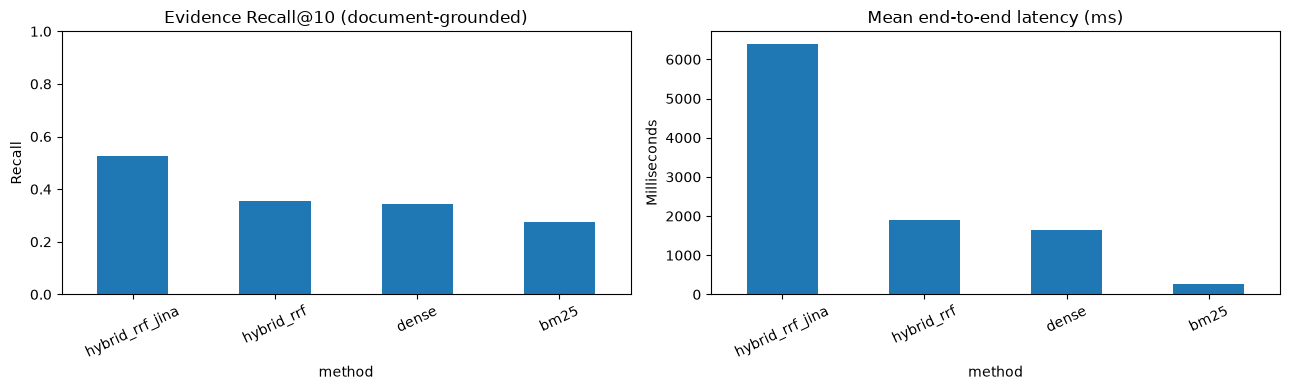

In [29]:
metric_summary = (
    metrics_df.groupby("method", dropna=False)
    .agg(
        n_queries=("query_id", "nunique"),
        document_hit_at_10=("document_hit_at_10", "mean"),
        evidence_recall_at_10=("evidence_recall_at_10", "mean"),
        quote_text_recall_at_10=("quote_text_recall_at_10", "mean"),
        mrr_at_10=("mrr_at_10", "mean"),
        mean_evidence_document_coverage=("evidence_document_coverage", "mean"),
    )
    .reset_index()
)
latency_summary = latency_df.groupby("method").agg(
    retrieval_latency_mean=("retrieval_latency_seconds", "mean"),
    retrieval_latency_median=("retrieval_latency_seconds", "median"),
    retrieval_latency_p95=("retrieval_latency_seconds", lambda values: values.quantile(0.95)),
    rerank_latency_mean=("rerank_latency_seconds", "mean"),
    rerank_latency_median=("rerank_latency_seconds", "median"),
    rerank_latency_p95=("rerank_latency_seconds", lambda values: values.quantile(0.95)),
    end_to_end_latency_mean=("end_to_end_latency_seconds", "mean"),
    end_to_end_latency_median=("end_to_end_latency_seconds", "median"),
    end_to_end_latency_p95=("end_to_end_latency_seconds", lambda values: values.quantile(0.95)),
).reset_index()
summary = metric_summary.merge(latency_summary, on="method", how="left")
jina_rows = latency_df[latency_df["method"] == "hybrid_rrf_jina"]
jina_success_count = int((jina_rows["jina_api_status"] == "success").sum())
jina_failure_count = int((jina_rows["jina_api_status"] == "failure").sum())
fallback_count = int(jina_rows["fallback_used"].sum())
summary["jina_api_success_queries"] = np.where(
    summary["method"] == "hybrid_rrf_jina", jina_success_count, 0
)
summary["jina_api_failure_queries"] = np.where(
    summary["method"] == "hybrid_rrf_jina", jina_failure_count, 0
)
summary["fallback_queries"] = np.where(
    summary["method"] == "hybrid_rrf_jina", fallback_count, 0
)
summary["jina_api_latency_mean"] = np.where(
    summary["method"] == "hybrid_rrf_jina",
    jina_rows["jina_api_latency_seconds"].mean(),
    0.0,
)
summary["jina_retry_wait_mean"] = np.where(
    summary["method"] == "hybrid_rrf_jina",
    jina_rows["jina_retry_wait_seconds"].mean(),
    0.0,
)
summary = summary.sort_values("evidence_recall_at_10", ascending=False)
display(summary)

print("\nReranker status counts:")
display(
    latency_df[latency_df["method"] == "hybrid_rrf_jina"]["rerank_outcome"]
    .value_counts(dropna=False)
    .rename_axis("status")
    .reset_index(name="queries")
)

import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
summary.set_index("method")["evidence_recall_at_10"].plot.bar(
    ax=axes[0], ylim=(0, 1), title="Evidence Recall@10 (document-grounded)"
)
summary.set_index("method")["end_to_end_latency_mean"].mul(1000).plot.bar(
    ax=axes[1], title="Mean end-to-end latency (ms)"
)
axes[0].set_ylabel("Recall")
axes[1].set_ylabel("Milliseconds")
for axis in axes:
    axis.tick_params(axis="x", labelrotation=25)
fig.tight_layout()
plt.show()


In [30]:
metrics_path = OUTPUT_DIR / "metrics_by_query.csv"
summary_path = OUTPUT_DIR / "rag_comparison_summary.csv"
latency_path = OUTPUT_DIR / "latency_by_query.csv"
predictions_path = OUTPUT_DIR / "retrieval_predictions.jsonl"
document_mapping_path = OUTPUT_DIR / "document_mapping_report.csv"
query_coverage_path = OUTPUT_DIR / "query_document_coverage.csv"
jina_status_path = OUTPUT_DIR / "jina_api_status_by_query.csv"

metrics_df.to_csv(metrics_path, index=False, encoding="utf-8-sig")
summary.to_csv(summary_path, index=False, encoding="utf-8-sig")
latency_df.to_csv(latency_path, index=False, encoding="utf-8-sig")
latency_df[latency_df["method"] == "hybrid_rrf_jina"].to_csv(
    jina_status_path, index=False, encoding="utf-8-sig"
)
document_mapping_df.to_csv(document_mapping_path, index=False, encoding="utf-8-sig")
query_document_coverage_df.to_csv(query_coverage_path, index=False, encoding="utf-8-sig")
predictions_df.to_json(predictions_path, orient="records", lines=True, force_ascii=False)

print("Saved:")
for output_path in [
    metrics_path,
    summary_path,
    latency_path,
    jina_status_path,
    predictions_path,
    document_mapping_path,
    query_coverage_path,
]:
    print(output_path)


Saved:
D:\Project_Github\gold assisstant\rag\rag_comparison\metrics_by_query.csv
D:\Project_Github\gold assisstant\rag\rag_comparison\rag_comparison_summary.csv
D:\Project_Github\gold assisstant\rag\rag_comparison\latency_by_query.csv
D:\Project_Github\gold assisstant\rag\rag_comparison\jina_api_status_by_query.csv
D:\Project_Github\gold assisstant\rag\rag_comparison\retrieval_predictions.jsonl
D:\Project_Github\gold assisstant\rag\rag_comparison\document_mapping_report.csv
D:\Project_Github\gold assisstant\rag\rag_comparison\query_document_coverage.csv


In [31]:
recall_pivot = metrics_df.pivot(
    index="query_id", columns="method", values="evidence_recall_at_10"
)
mrr_pivot = metrics_df.pivot(index="query_id", columns="method", values="mrr_at_10")
status_pivot = metrics_df.pivot(index="query_id", columns="method", values="jina_api_status")
outcome_pivot = metrics_df.pivot(index="query_id", columns="method", values="rerank_outcome")
http_pivot = metrics_df.pivot(index="query_id", columns="method", values="jina_http_status")
error_pivot = metrics_df.pivot(index="query_id", columns="method", values="jina_error_reason")
query_lookup = {query["query_id"]: query["query"] for query in queries_eval}
comparison = pd.DataFrame(index=recall_pivot.index)
comparison["query"] = pd.Series(query_lookup)
comparison["jina_api_status"] = status_pivot["hybrid_rrf_jina"]
comparison["rerank_outcome"] = outcome_pivot["hybrid_rrf_jina"]
comparison["jina_http_status"] = http_pivot["hybrid_rrf_jina"]
comparison["jina_error_reason"] = error_pivot["hybrid_rrf_jina"]
comparison["jina_was_applied"] = comparison["jina_api_status"] == "success"
for method in ("bm25", "dense", "hybrid_rrf", "hybrid_rrf_jina"):
    comparison[f"{method}_evidence_recall_at_10"] = recall_pivot[method]
    comparison[f"{method}_mrr_at_10"] = mrr_pivot[method]

for baseline in ("dense", "hybrid_rrf"):
    delta_column = f"jina_minus_{baseline}_evidence_recall_at_10"
    comparison[delta_column] = (
        comparison["hybrid_rrf_jina_evidence_recall_at_10"]
        - comparison[f"{baseline}_evidence_recall_at_10"]
    )
    comparison[f"jina_vs_{baseline}"] = np.select(
        [comparison[delta_column] > 1e-12, comparison[delta_column] < -1e-12],
        ["improved", "worsened"],
        default="unchanged",
    )

comparison = comparison.reset_index()
comparison_path = OUTPUT_DIR / "jina_query_comparison.csv"
comparison.to_csv(comparison_path, index=False, encoding="utf-8-sig")
jina_success_comparison = comparison.loc[comparison["jina_was_applied"]].copy()
jina_success_path = OUTPUT_DIR / "jina_successful_queries_comparison.csv"
jina_success_comparison.to_csv(jina_success_path, index=False, encoding="utf-8-sig")
jina_failure_comparison = comparison.loc[comparison["jina_api_status"] == "failure"].copy()
jina_failure_path = OUTPUT_DIR / "jina_failed_queries_comparison.csv"
jina_failure_comparison.to_csv(jina_failure_path, index=False, encoding="utf-8-sig")
display(comparison)
print("Successful Jina calls:", len(jina_success_comparison), "of", len(comparison))
print("Failed Jina calls / fallback queries:", len(jina_failure_comparison))
for baseline in ("dense", "hybrid_rrf"):
    result_column = f"jina_vs_{baseline}"
    delta_column = f"jina_minus_{baseline}_evidence_recall_at_10"
    successful = jina_success_comparison
    print(f"\nSuccessful Jina versus {baseline}:")
    display(successful[result_column].value_counts().rename_axis("result").reset_index(name="queries"))
    print("Mean Evidence Recall@10 delta:", successful[delta_column].mean())
    print("Mean MRR@10 delta:", (successful[f"hybrid_rrf_jina_mrr_at_10"] - successful[f"{baseline}_mrr_at_10"]).mean())
print("All-query comparison saved:", comparison_path)
print("Successful-Jina-only comparison saved:", jina_success_path)
print("Failed-Jina comparison saved:", jina_failure_path)


,query_id,query,jina_api_status,rerank_outcome,jina_http_status,jina_error_reason,jina_was_applied,bm25_evidence_recall_at_10,bm25_mrr_at_10,dense_evidence_recall_at_10,dense_mrr_at_10,hybrid_rrf_evidence_recall_at_10,hybrid_rrf_mrr_at_10,hybrid_rrf_jina_evidence_recall_at_10,hybrid_rrf_jina_mrr_at_10,jina_minus_dense_evidence_recall_at_10,jina_vs_dense,jina_minus_hybrid_rrf_evidence_recall_at_10,jina_vs_hybrid_rrf
0,gtv2_000001,ตามรายงาน CPI ของสหรัฐฯ สำหรับ July 2016 ค่า C...,success,jina_success,200.0,NaN,True,0.0,0.000000,0.0,0.000,0.0,0.000000,0.0,0.000000,0.0,unchanged,0.0,unchanged
1,gtv2_000002,What 12-month change in the all-items index di...,success,jina_success,200.0,NaN,True,0.0,0.000000,1.0,0.125,0.0,0.000000,1.0,0.250000,0.0,unchanged,1.0,improved
2,gtv2_000003,According to the U.S. CPI release for January ...,success,jina_success,200.0,NaN,True,0.0,0.500000,0.0,0.000,0.0,0.500000,0.0,0.111111,0.0,unchanged,0.0,unchanged
3,gtv2_000004,รายงาน CPI ของสหรัฐฯ สำหรับ January 2023 ระบุว...,success,jina_success,200.0,NaN,True,0.0,0.000000,0.0,0.000,0.0,0.000000,1.0,0.100000,1.0,improved,1.0,improved
4,gtv2_000005,ตามรายงาน CPI ของสหรัฐฯ สำหรับ December 2025 ค...,success,jina_success,200.0,NaN,True,0.0,0.000000,1.0,0.250,1.0,0.111111,1.0,1.000000,0.0,unchanged,0.0,unchanged
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
109,gtv2_000110,เปรียบเทียบราคาขายออกทองคำแท่งที่ Thai PBS ราย...,success,jina_success,200.0,NaN,True,1.0,1.000000,1.0,1.000,1.0,1.000000,1.0,1.000000,0.0,unchanged,0.0,unchanged
110,gtv2_000111,"For January 2026, what were the monthly change...",success,jina_success,200.0,NaN,True,0.0,0.000000,1.0,0.200,1.0,0.500000,1.0,0.500000,0.0,unchanged,0.0,unchanged
111,gtv2_000112,In the December 2022 U.S. Employment Situation...,success,jina_success,200.0,NaN,True,1.0,0.500000,1.0,1.000,1.0,1.000000,1.0,0.500000,0.0,unchanged,0.0,unchanged
112,gtv2_000113,ตามบทความ Thai PBS เรื่อง “สรุปราคาทองคำ 20 ต....,success,jina_success,200.0,NaN,True,1.0,0.142857,0.0,0.000,0.0,0.000000,1.0,0.500000,1.0,improved,1.0,improved


Successful Jina calls: 114 of 114
Failed Jina calls / fallback queries: 0

Successful Jina versus dense:


,result,queries
0,unchanged,87
1,improved,24
2,worsened,3


Mean Evidence Recall@10 delta: 0.18421052631578946
Mean MRR@10 delta: 0.19318434976329713

Successful Jina versus hybrid_rrf:


,result,queries
0,unchanged,87
1,improved,23
2,worsened,4


Mean Evidence Recall@10 delta: 0.17105263157894737
Mean MRR@10 delta: 0.1883249791144528
All-query comparison saved: D:\Project_Github\gold assisstant\rag\rag_comparison\jina_query_comparison.csv
Successful-Jina-only comparison saved: D:\Project_Github\gold assisstant\rag\rag_comparison\jina_successful_queries_comparison.csv
Failed-Jina comparison saved: D:\Project_Github\gold assisstant\rag\rag_comparison\jina_failed_queries_comparison.csv
